# Isotropic 512×512 → 128×128 — Data Inspection

Use this notebook to sanity-check the random-crop pipeline: load the DNS snapshots, inspect checkerboard tiles, and visualize random HR/LR patches before training.

In [2]:
import os
import sys
from pathlib import Path
import json
import random

import sys
import json
import warnings
from pathlib import Path

def find_project_root(start: Path, target="models", max_up: int = 8) -> Path:
    root = start.resolve()
    for _ in range(max_up):
        if (root / target).exists():
            return root
        if root.parent == root:
            break
        root = root.parent
    raise FileNotFoundError(f"Could not find '{target}' above {start}")


ROOT = find_project_root(Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import h5py
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from utils.sr_datasets import RandomCropSRDataset, TiledSRDataset, create_snapshot_splits, compute_global_stats, compute_multifield_stats

plt.rcParams['figure.dpi'] = 140
plt.rcParams['axes.grid'] = False
np.random.seed(42)
random.seed(42)


os.environ.setdefault('NCCL_SHM_DISABLE', '1')
print('Project root:', ROOT)


Project root: /workspaces/jhtdb-ml


In [3]:
import yaml

CONFIG_PATH = ROOT / 'configs/sr_unet_meteo_512crops.yaml'
with open(CONFIG_PATH) as fp:
    config = yaml.safe_load(fp)

print('Loaded config:', CONFIG_PATH)
print(json.dumps({
    'experiment': config['experiment']['name'],
    'h5_path': config['data']['h5_path'],
    'scale_factor': config['model']['scale_factor'],
    'train_snapshots': config['data']['split']['train_snapshots'],
    'val_snapshots': config['data']['split']['val_snapshots'],
    'test_snapshots': config['data']['split']['test_snapshots'],
}, indent=2))


Loaded config: /workspaces/jhtdb-ml/configs/sr_unet_meteo_512crops.yaml
{
  "experiment": "sr_unet_meteo_isotropic_512crops",
  "h5_path": "data/raw/isotropic_xy_512/isotropic_xy_512.h5",
  "scale_factor": 4,
  "train_snapshots": 700,
  "val_snapshots": 150,
  "test_snapshots": 149
}


In [4]:
# Load the isotropic DNS fields (ux, uy, omega_z)
import time
h5_path = (ROOT / config['data']['h5_path']).resolve()
print('Reading:', h5_path)
start = time.time()
fields = {'ux': [], 'uy': [], 'omega_z': []}
times = []
with h5py.File(h5_path, 'r') as h5:
    snaps = h5['snapshots']
    keys = sorted(snaps.keys())
    for key in keys:
        grp = snaps[key]
        for name in fields:
            fields[name].append(np.asarray(grp[name]))
        times.append(float(np.asarray(grp['time'])))
ux = np.stack(fields['ux'])
uy = np.stack(fields['uy'])
omega = np.stack(fields['omega_z'])
print(f"Loaded {omega.shape[0]} snapshots in {time.time()-start:.1f}s")
print('Field shapes:', ux.shape, uy.shape, omega.shape)


Reading: /workspaces/jhtdb-ml/data/raw/isotropic_xy_512/isotropic_xy_512.h5
Loaded 999 snapshots in 19.2s
Field shapes: (999, 512, 512) (999, 512, 512) (999, 512, 512)


In [14]:
# Build snapshot splits and datasets for inspection
split_cfg = config['data']['split']
train_idx, val_idx, test_idx = create_snapshot_splits(
    total_snapshots=omega.shape[0],
    train_snapshots=split_cfg['train_snapshots'],
    val_snapshots=split_cfg['val_snapshots'],
    test_snapshots=split_cfg['test_snapshots'],
)
print('Splits:')
print(f"  Train: {train_idx[0]}-{train_idx[-1]} ({len(train_idx)})")
print(f"  Val:   {val_idx[0]}-{val_idx[-1]} ({len(val_idx)})")
print(f"  Test:  {test_idx[0]}-{test_idx[-1]} ({len(test_idx)})")

scale = int(config['model']['scale_factor'])
crop_cfg = config['data'].get('crops', {})
patch_size_hr = int(crop_cfg.get('patch_size_hr', 128))
train_crops = int(crop_cfg.get('train_crops_per_snapshot', 8))

norm_method = config['data']['normalization']['method']
if norm_method == 'global':
    mu, sigma = compute_global_stats(omega, train_idx)
    stats = compute_multifield_stats(ux, uy, omega, train_idx)
else:
    mu = sigma = None
    stats = None

train_dataset = RandomCropSRDataset(
    omega_seq=omega,
    ux_seq=ux,
    uy_seq=uy,
    indices=train_idx,
    patch_size_hr=patch_size_hr,
    scale=scale,
    num_crops_per_snapshot=train_crops,
    normalize=norm_method,
    mu=mu,
    sigma=sigma,
    stats=stats,
)
val_dataset = TiledSRDataset(
    omega_seq=omega,
    ux_seq=ux,
    uy_seq=uy,
    indices=val_idx,
    patch_size_hr=patch_size_hr,
    scale=scale,
    normalize=norm_method,
    mu=mu,
    sigma=sigma,
    stats=stats,
)
print(f"Train samples: {len(train_dataset)} ({train_crops} crops / snapshot)")
print(f"Val tiles: {len(val_dataset)} (checkerboard → 8 tiles / snapshot)")


Splits:
  Train: 0-699 (700)
  Val:   700-849 (150)
  Test:  850-998 (149)
Train samples: 5600 (8 crops / snapshot)
Val tiles: 1200 (checkerboard → 8 tiles / snapshot)


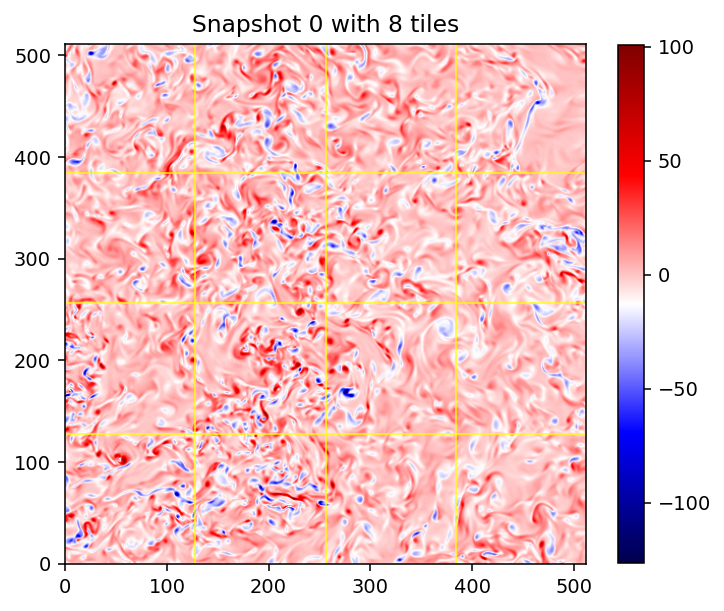

In [15]:
# Visualize a parent snapshot with checkerboard tiles overlayed
from matplotlib.patches import Rectangle
sample_snap = train_idx[0]
field = omega[sample_snap]
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(field.T, cmap='seismic', origin='lower')
for (y0, x0) in val_dataset.tile_positions:
    rect = Rectangle((x0, y0), patch_size_hr, patch_size_hr,
                     linewidth=1.0, edgecolor='yellow', facecolor='none', alpha=0.7)
    ax.add_patch(rect)
ax.set_title(f'Snapshot {sample_snap} with {len(val_dataset.tile_positions)} tiles')
plt.colorbar(im, ax=ax, shrink=0.8)
plt.show()


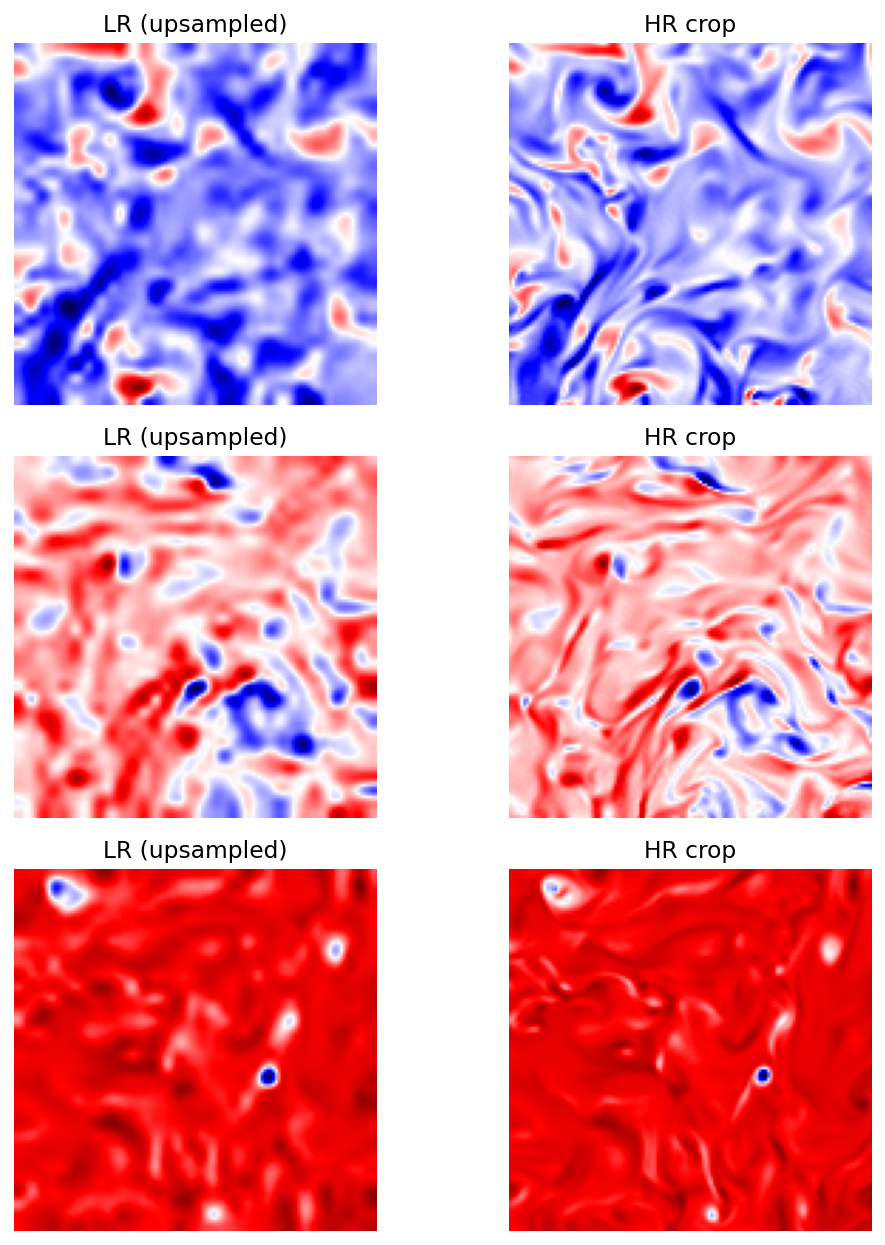

In [16]:
# Random HR/LR crop comparisons
num_examples = 3
fig, axes = plt.subplots(num_examples, 2, figsize=(8, 3 * num_examples))
for row in range(num_examples):
    sample = train_dataset[random.randint(0, len(train_dataset) - 1)]
    hr = sample['hr_omega'].numpy()
    lr = sample['lr_omega'].numpy()
    lr_up = (
        F.interpolate(torch.from_numpy(lr).unsqueeze(0), size=patch_size_hr, mode='bicubic', align_corners=False)
        .squeeze(0)
        .numpy()
    )
    axes[row, 0].imshow(lr_up[0].T, cmap='seismic', origin='lower')
    axes[row, 0].set_title('LR (upsampled)')
    axes[row, 0].axis('off')
    axes[row, 1].imshow(hr.T, cmap='seismic', origin='lower')
    axes[row, 1].set_title('HR crop')
    axes[row, 1].axis('off')
plt.tight_layout()
plt.show()


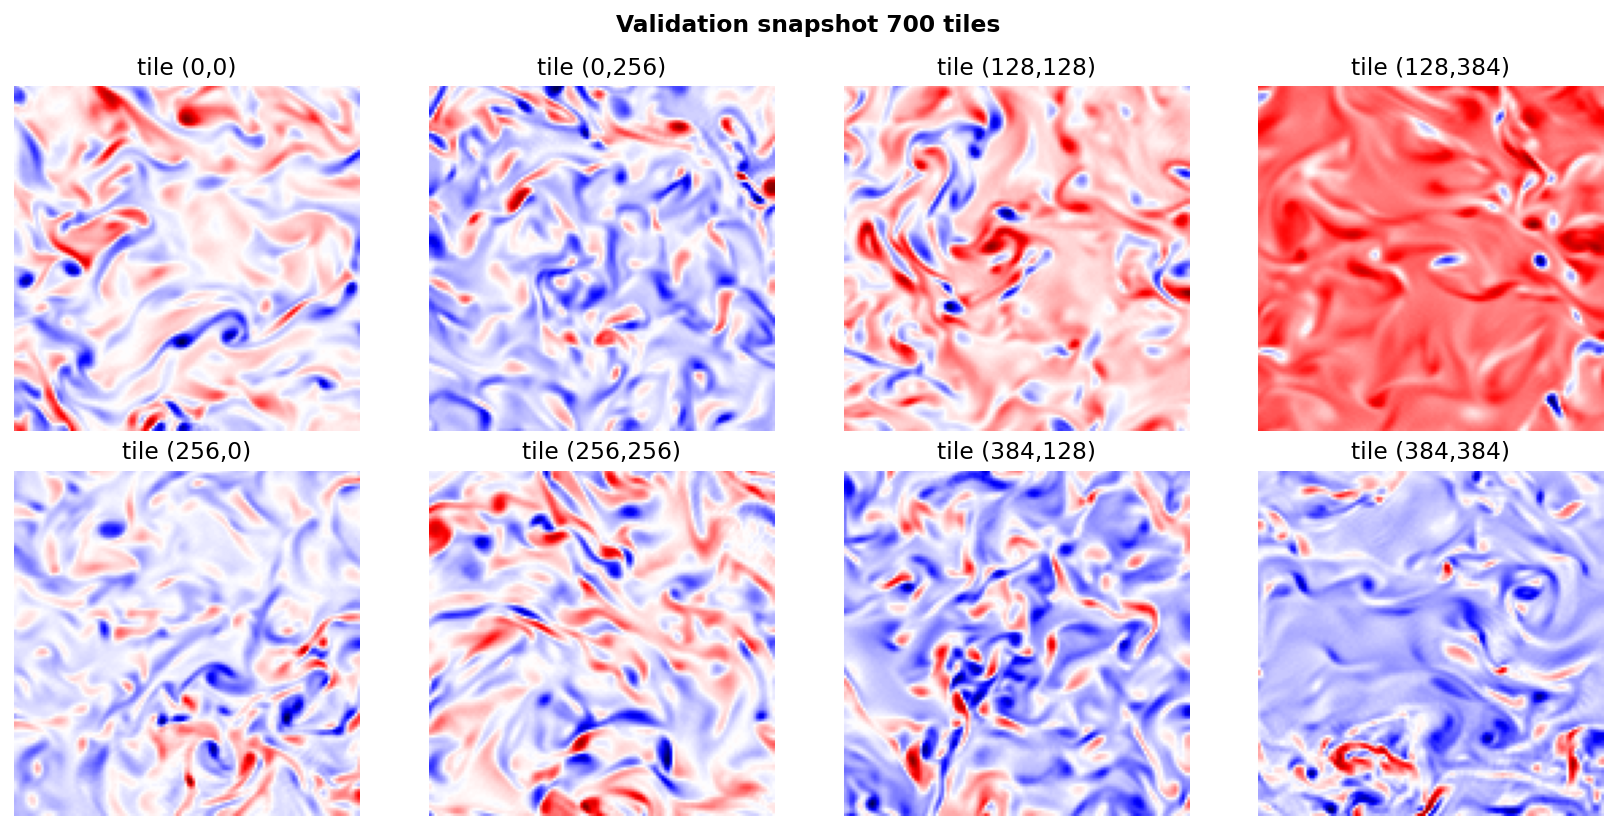

In [17]:
# Deterministic tile quicklook (validation snapshot)
val_snap = val_idx[0]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (y0, x0) in zip(axes.flat, val_dataset.tile_positions):
    tile = omega[val_snap, y0:y0+patch_size_hr, x0:x0+patch_size_hr]
    ax.imshow(tile.T, cmap='seismic', origin='lower')
    ax.set_title(f'tile ({y0},{x0})')
    ax.axis('off')
plt.suptitle(f'Validation snapshot {val_snap} tiles', fontweight='bold')
plt.tight_layout()
plt.show()
